# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [12]:
ROLL_NO = 1024170405          # <-- your full roll number
NAME = "Siya"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [13]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [14]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [15]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170405   Name: Siya   Fingerprint: 26426300   Tickets: 12

Ticket_ID                                                                               Ticket_Text
      T01                                                    Only 2 of 30 PCs boot after 3.5 hours.
      T02                                  The Python is not working. It works on another computer.
      T03       Projector failed to open when connected to campus Wi-Fi. I don't know what changed.
      T04                              The printer is running slowly. It works on another computer.
      T05 I am unable to use the VPN when connected to campus Wi-Fi. The same problem occurs again.
      T06                      VPN keeps asking for login while uploading the file. This is urgent.
      T07                                       The VPN was working yesterday. It worked yesterday.
      T08                                                             The LMS says 'Not Submitted'.
      T09               

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [21]:
# Your code
# Q1: Preprocessing

results = []

for _, row in df.iterrows():
    processed = process_ticket(row["Ticket_Text"])

    results.append({
        "Ticket_ID": row["Ticket_ID"],
        "Number of Sentences": len(processed["sentences"]),
        "Number of Tokens": len(processed["tokens"]),
        "Number of Punctuation Tokens": len(processed["punct"]),
        "Number of Stopwords": len(processed["stops"]),
        "Number of Unique Tokens": len(set(processed["tokens"])),
        "Number of Final Tokens": len(processed["final"])
    })

# Create table
q1_table = pd.DataFrame(results)

# Add total row for count-based columns
total_row = {
    "Ticket_ID": "TOTAL",
    "Number of Sentences": q1_table["Number of Sentences"].sum(),
    "Number of Tokens": q1_table["Number of Tokens"].sum(),
    "Number of Punctuation Tokens": q1_table["Number of Punctuation Tokens"].sum(),
    "Number of Stopwords": q1_table["Number of Stopwords"].sum(),
    "Number of Unique Tokens": q1_table["Number of Unique Tokens"].sum(),
    "Number of Final Tokens": q1_table["Number of Final Tokens"].sum()
}

q1_table = pd.concat(
    [q1_table, pd.DataFrame([total_row])],
    ignore_index=True
)

display(q1_table)

,Ticket_ID,Number of Sentences,Number of Tokens,Number of Punctuation Tokens,Number of Stopwords,Number of Unique Tokens,Number of Final Tokens
0,T01,1,10,1,3,10,6
1,T02,2,12,2,5,11,5
2,T03,2,17,2,6,15,9
3,T04,2,12,2,4,11,6
4,T05,2,19,2,9,16,8
5,T06,2,14,2,5,13,7
6,T07,2,10,2,3,8,5
7,T08,1,7,2,1,7,4
8,T09,1,11,2,5,8,4
9,T10,2,12,2,2,11,8


In [22]:
# Display details for one selected focus ticket

selected_id = FOCUS[0]

ticket_text = df.loc[
    df["Ticket_ID"] == selected_id,
    "Ticket_Text"
].iloc[0]

processed = process_ticket(ticket_text)

print("Selected Ticket:", selected_id)
print("Ticket Text:", ticket_text)

print("\nActual Tokens:")
print(processed["tokens"])

print("\nPunctuation Tokens:")
print(processed["punct"])

print("\nStopwords:")
print(processed["stops"])

print("\nFinal Tokens:")
print(processed["final"])

Selected Ticket: T04
Ticket Text: The printer is running slowly. It works on another computer.

Actual Tokens:
['the', 'printer', 'is', 'running', 'slowly', '.', 'it', 'works', 'on', 'another', 'computer', '.']

Punctuation Tokens:
['.', '.']

Stopwords:
['the', 'is', 'it', 'on']

Final Tokens:
['printer', 'running', 'slowly', 'works', 'another', 'computer']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* Some final tokens are not real words, such as n't, 's, and ca. They come from contractions. NLTK's word_tokenize() splits contractions into separate tokens, for example, "can't" becomes ca + n't and "it's" becomes it + 's. Since these tokens are not punctuation and may not be in the stopword list, they remain in the final tokens.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [23]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code
import re

text = " ".join(df["Ticket_Text"])

# Words longer than 5 letters
long_words = re.findall(r'\b[A-Za-z]{6,}\b', text)

# Numbers, keeping decimals/version numbers together
numbers = re.findall(r'\b\d+(?:\.\d+)*\b', text)

# Capitalized words
capitalized_words = re.findall(r'\b[A-Z][a-zA-Z]*\b', text)

# Words beginning with a vowel
vowel_words = re.findall(r'\b[aeiouAEIOU][a-zA-Z]*\b', text)

print("Words longer than 5 letters:", long_words)
print("Numbers:", numbers)
print("Capitalized words:", capitalized_words)
print("Words beginning with a vowel:", vowel_words)

Words longer than 5 letters: ['Python', 'working', 'another', 'computer', 'Projector', 'failed', 'connected', 'campus', 'changed', 'printer', 'running', 'slowly', 'another', 'computer', 'unable', 'connected', 'campus', 'problem', 'occurs', 'asking', 'uploading', 'urgent', 'working', 'yesterday', 'worked', 'yesterday', 'Submitted', 'laptop', 'server', 'printer', 'yesterday', 'Please', 'helpdesk', 'university', 'getting', 'logged', 'during', 'urgent']
Numbers: ['2', '30', '3.5']
Capitalized words: ['Only', 'PCs', 'The', 'Python', 'It', 'Projector', 'Wi', 'Fi', 'I', 'The', 'It', 'I', 'VPN', 'Wi', 'Fi', 'The', 'VPN', 'This', 'The', 'VPN', 'It', 'The', 'LMS', 'Not', 'Submitted', 'It', 'I', 'Please', 'Email', 'I', 'This']
Words beginning with a vowel: ['Only', 'of', 'after', 'is', 'It', 'on', 'another', 'open', 'I', 'is', 'It', 'on', 'another', 'I', 'am', 'unable', 'use', 'occurs', 'again', 'asking', 'uploading', 'is', 'urgent', 'It', 'It', 'it', 'I', 'open', 'Email', 'at', 'university', 'ed

In [24]:
# Replace email addresses, URLs and phone numbers

email_pattern = r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b'
url_pattern = r'https?://\S+|www\.\S+'
phone_pattern = r'(?<!\w)(?:\+91[\s-]?)?(?:\d{5}[\s-]?\d{5}|\d{4}[\s-]?\d{3}[\s-]?\d{4})(?!\w)'

for line in TEST_LINES:
    result = re.sub(email_pattern, "<EMAIL>", line)
    result = re.sub(url_pattern, "<URL>", result)
    result = re.sub(phone_pattern, "<PHONE>", result)

    print(result)

Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>
Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* 3 capitalized words are capitalized only because they start a sentence: Mail, Call, and The.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [25]:
# Your code
import re
from nltk.tokenize import RegexpTokenizer, word_tokenize

# One pattern that keeps special structures together
pattern = (
    r"https?://[A-Za-z0-9./?=&_%#:-]+|"
    r"www\.[A-Za-z0-9./?=&_%#:-]+|"
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"
    r"(?:\+91[\s-]?)?(?:\d{5}[\s-]?\d{5}|\d{4}[\s-]\d{3}[\s-]\d{4})|"
    r"\d+(?:\.\d+)+|"
    r"[A-Za-z]+(?:'[A-Za-z]+)|"
    r"[A-Za-z]+(?:-[A-Za-z]+)+|"
    r"[A-Za-z]+|"
    r"\d+(?:\.\d+)*|"
    r"[^\w\s]"
)

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

# Run on TEST_LINES
print("===== TEST LINES =====")

for line in TEST_LINES:
    print("\nOriginal:")
    print(line)

    print("\nmy_tokenize:")
    print(my_tokenize(line))

    print("\nword_tokenize:")
    print(word_tokenize(line))


# Compare on all tickets
different_tickets = []

for _, row in df.iterrows():
    custom = my_tokenize(row["Ticket_Text"])
    standard = word_tokenize(row["Ticket_Text"])

    if custom != standard:
        different_tickets.append(row["Ticket_ID"])

print("\n===== COMPARISON =====")
print("Number of tickets tokenized differently:", len(different_tickets))
print("Tickets:", different_tickets)

===== TEST LINES =====

Original:
Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.

my_tokenize:
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']

word_tokenize:
['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Original:
Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.

my_tokenize:
['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']

word_tokenize:
['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Original:
The state-of-the-art lab isn't open; 

In [26]:
for _, row in df.iterrows():
    custom = my_tokenize(row["Ticket_Text"])
    standard = word_tokenize(row["Ticket_Text"])

    if custom != standard:
        print("\nTicket:", row["Ticket_ID"])
        print("Text:", row["Ticket_Text"])
        print("my_tokenize :", custom)
        print("word_tokenize:", standard)


Ticket: T03
Text: Projector failed to open when connected to campus Wi-Fi. I don't know what changed.
my_tokenize : ['Projector', 'failed', 'to', 'open', 'when', 'connected', 'to', 'campus', 'Wi-Fi', '.', 'I', "don't", 'know', 'what', 'changed', '.']
word_tokenize: ['Projector', 'failed', 'to', 'open', 'when', 'connected', 'to', 'campus', 'Wi-Fi', '.', 'I', 'do', "n't", 'know', 'what', 'changed', '.']

Ticket: T08
Text: The LMS says 'Not Submitted'.
my_tokenize : ['The', 'LMS', 'says', "'", 'Not', 'Submitted', "'", '.']
word_tokenize: ['The', 'LMS', 'says', "'Not", 'Submitted', "'", '.']

Ticket: T09
Text: It's not the laptop; it's the server.
my_tokenize : ["It's", 'not', 'the', 'laptop', ';', "it's", 'the', 'server', '.']
word_tokenize: ['It', "'s", 'not', 'the', 'laptop', ';', 'it', "'s", 'the', 'server', '.']

Ticket: T10
Text: I can't open the printer since yesterday. Please help.
my_tokenize : ['I', "can't", 'open', 'the', 'printer', 'since', 'yesterday', '.', 'Please', 'help', 

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* X tickets are tokenized differently by my_tokenize() and word_tokenize(). The main differences are that my_tokenize() keeps contractions such as isn't as one token, keeps hyphenated words such as Wi-Fi and state-of-the-art together, and keeps decimals/version numbers such as 95.5 and 2.0.1 together. It also keeps email addresses, URLs, and phone numbers as single tokens, whereas word_tokenize() generally splits these into multiple tokens.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [27]:
# Your code
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag, word_tokenize
import nltk
import pandas as pd

# Download required resources
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')

# Get unique final tokens from all tickets
unique_final_tokens = set()

for text in df["Ticket_Text"]:
    processed = process_ticket(text)
    unique_final_tokens.update(processed["final"])

unique_final_tokens = sorted(unique_final_tokens)

print("Number of unique final tokens:", len(unique_final_tokens))

Number of unique final tokens: 55


[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


In [29]:
porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    elif tag.startswith("V"):
        return "v"
    elif tag.startswith("N"):
        return "n"
    elif tag.startswith("R"):
        return "r"
    else:
        return "n"

In [30]:
from collections import Counter

suffixes = Counter()

for word in unique_final_tokens:
    for suffix in ["ing", "ed", "ly", "es", "s"]:
        if word.endswith(suffix) and len(word) > len(suffix) + 2:
            suffixes[suffix] += 1

print(suffixes)

Counter({'s': 6, 'ed': 6, 'ing': 5, 'ly': 1})


In [33]:
regexp_stemmer = RegexpStemmer(r'ing$', min=3)
chosen_suffix = "ing"

results = []

tagged_words = pos_tag(unique_final_tokens)

for word, tag in tagged_words:
    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regexp_result = regexp_stemmer.stem(word)

    wordnet_pos = get_wordnet_pos(tag)
    lemma_result = lemmatizer.lemmatize(word, pos=wordnet_pos)

    if len({porter_result, lancaster_result, regexp_result, lemma_result}) > 1:
        results.append({
            "Word": word,
            "Porter": porter_result,
            "Lancaster": lancaster_result,
            "Regexp": regexp_result,
            "WordNet": lemma_result
        })

q4_table = pd.DataFrame(results)

print("Chosen suffix:", chosen_suffix)
display(q4_table)

Chosen suffix: ing


,Word,Porter,Lancaster,Regexp,WordNet
0,another,anoth,anoth,another,another
1,campus,campu,camp,campus,campus
2,changed,chang,chang,changed,change
3,computer,comput,comput,computer,computer
4,connected,connect,connect,connected,connect
5,failed,fail,fail,failed,fail
6,file,file,fil,file,file
7,getting,get,get,gett,get
8,hours,hour,hour,hours,hour
9,keeps,keep,keep,keeps,keep


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Over-stemming: another → anoth with Porter Stemmer, which removes too much and produces a non-word.
Under-stemming: getting → gett with the RegexpStemmer, because the simple ing suffix rule removes ing without handling the doubled t.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

===== CORPUS STATISTICS =====
S1:
  Total tokens   = 147
  Unique tokens  = 83
  TTR            = 0.5646

S2:
  Total tokens   = 124
  Unique tokens  = 79
  TTR            = 0.6371

S3:
  Total tokens   = 71
  Unique tokens  = 55
  TTR            = 0.7746

S4:
  Total tokens   = 71
  Unique tokens  = 52
  TTR            = 0.7324

===== TOP 10 WORDS OF S1 =====
[('.', 20), ('the', 12), ('it', 5), ('is', 4), ('to', 4), ('i', 4), ('vpn', 3), ('yesterday', 3), ('of', 2), ('not', 2)]

===== TOP 10 WORDS OF S3 =====
[('vpn', 3), ('yesterday', 3), ('working', 2), ('works', 2), ('another', 2), ('computer', 2), ('open', 2), ('connected', 2), ('campus', 2), ('wi-fi', 2)]


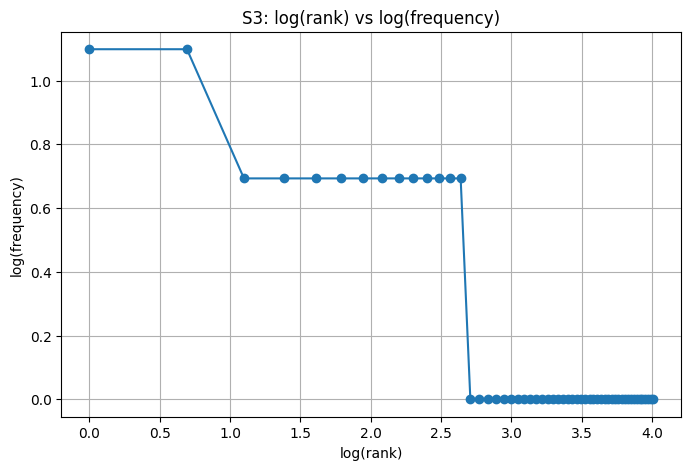


===== TOP 5 BIGRAMS OF S1 =====
[(('.', 'the'), 5), (('.', 'it'), 4), (('.', 'i'), 4), (('yesterday', '.'), 3), (('it', 'works'), 2)]

===== TOP 5 BIGRAMS OF S3 =====
[(('works', 'another'), 2), (('another', 'computer'), 2), (('connected', 'campus'), 2), (('campus', 'wi-fi'), 2), (('2', '30'), 1)]


In [34]:
# Your code
# Q5: Corpus statistics

from collections import Counter
from nltk.stem import PorterStemmer
from nltk.util import ngrams
import math
import matplotlib.pyplot as plt

porter = PorterStemmer()

# Create S1, S2, S3
S1 = []
S2 = []
S3 = []

for text in df["Ticket_Text"]:
    processed = process_ticket(text)

    # S1: all tokens
    S1.extend(processed["tokens"])

    # S2: tokens without punctuation
    S2.extend([t for t in processed["tokens"] if t not in processed["punct"]])

    # S3: final tokens
    S3.extend(processed["final"])

# S4: S3 after Porter stemming
S4 = [porter.stem(token) for token in S3]


# Function to calculate statistics
def corpus_stats(tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total > 0 else 0
    return total, unique, ttr


# Calculate statistics
stats = {
    "S1": corpus_stats(S1),
    "S2": corpus_stats(S2),
    "S3": corpus_stats(S3),
    "S4": corpus_stats(S4)
}

print("===== CORPUS STATISTICS =====")

for name, (total, unique, ttr) in stats.items():
    print(f"{name}:")
    print(f"  Total tokens   = {total}")
    print(f"  Unique tokens  = {unique}")
    print(f"  TTR            = {ttr:.4f}")
    print()


# Top 10 words of S1 and S3
print("===== TOP 10 WORDS OF S1 =====")
print(Counter(S1).most_common(10))

print("\n===== TOP 10 WORDS OF S3 =====")
print(Counter(S3).most_common(10))


# Log(rank) vs log(frequency) for S3
freq = Counter(S3)
ranked = sorted(freq.values(), reverse=True)

ranks = list(range(1, len(ranked) + 1))

log_ranks = [math.log(r) for r in ranks]
log_freq = [math.log(f) for f in ranked]

plt.figure(figsize=(8, 5))
plt.plot(log_ranks, log_freq, marker='o')
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("S3: log(rank) vs log(frequency)")
plt.grid(True)
plt.show()


# Top 5 bigrams of S1
bigrams_S1 = Counter(ngrams(S1, 2))

print("\n===== TOP 5 BIGRAMS OF S1 =====")
print(bigrams_S1.most_common(5))


# Top 5 bigrams of S3
bigrams_S3 = Counter(ngrams(S3, 2))

print("\n===== TOP 5 BIGRAMS OF S3 =====")
print(bigrams_S3.most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR increases from S1 to S3 because punctuation and stopwords are removed, reducing the total number of tokens faster than the number of unique tokens. From S3 to S4, Porter stemming reduces some different words to the same stem, so the number of unique tokens decreases from 55 to 52 while the total remains 71. Therefore, TTR decreases from 0.7746 to 0.7324.

(a) TTR increases from S1 to S3 because punctuation and stopwords are removed, reducing the total number of tokens faster than the number of unique tokens. From S3 to S4, Porter stemming reduces some different words to the same stem, so unique tokens decrease from 55 to 52 while total tokens remain 71. Therefore, TTR decreases from 0.7746 to 0.7324.

(b) For example, can't is tokenized by word_tokenize() as ca and n't, while my custom tokenizer keeps can't as one token. The custom tokenizer preserves contractions as single tokens.

(c) Porter stemming can produce undesirable results such as another → anoth, which is not a meaningful word.

(d) For example, changed is lemmatized as change using POS-aware WordNet lemmatization, while stemming gives chang. Lemmatization therefore preserves the meaningful word better.